# Two-Stage OTA
## TODO : 
 -- Opti pour noise ou gain plus précis  
 -- ratio gm 2nd étage pour pas d'offset  
 -- Sizing pour pas de M2 delirant

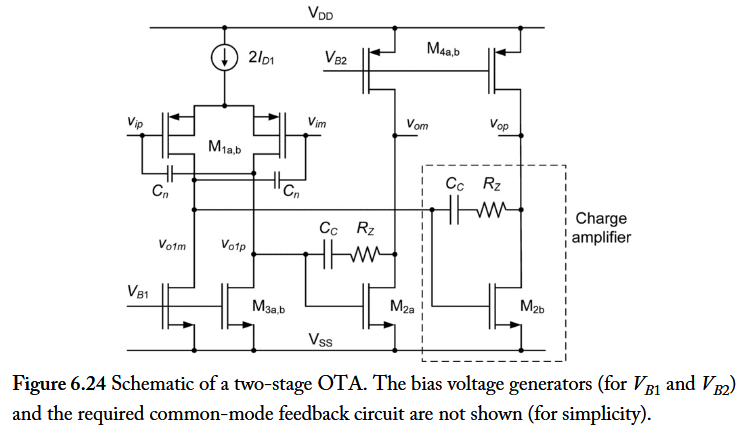

## No switch cap function

## Step 1 : import libs

In [242]:
import numpy as np
import scipy.constants as sc
import catppuccin
import matplotlib.pyplot as plt
import sys; sys.path.append('../..')
import adri
from pygmid import Lookup as lk
# pmos4 = lk('../../lookup_table/035/pmos4.mat')
# nmos4 = lk('../../lookup_table/035/nmos4.mat')
pmos4 = lk('../../lookup_table/040/pmos_T40N.mat')
nmos4 = lk('../../lookup_table/040/nmos_T40N.mat')
# setup matplotlib
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams.update({"axes.grid": True})
from scipy.interpolate import interp1d
def interp1(x, y, value):
    # Interpolation function
    # Perform cubic interpolation using interp1d
    f = interp1d(x, y, kind='cubic')
    return f(value)


In [243]:
def two_stage_sr_opti_noSC(nmos, pmos, s, d):
    kBT = 1.3806488e-23 * 300
    cltot_cc_arr = np.atleast_1d(d['cltot_cc'])
    N = 1   # axe 0
    M = len(cltot_cc_arr)  # axe 1
    m1 = {k: np.full((N, M), np.nan) for k in ['W','gm','GM_ID','cgg','cgd','cdd','ft','ID']}
    m2 = {k: np.full((N, M), np.nan) for k in ['W','gm','GM_ID','cgg','cgd','cdd','ft','ID','cgs','fts']}
    m3 = {k: np.full((N, M), np.nan) for k in ['W','GM_ID','cdd']}
    m4 = {k: np.full((N, M), np.nan) for k in ['W','GM_ID','cdd']}
    p  = {k: np.full((N, M), np.nan) for k in ['cc','cltot','cl','c1','rz','cn','rself1','rself2','cc_add']}
    m1['L'] = d['L1']
    m2['L'] = d['L2']
    m3['L'] = d['L3']
    m4['L'] = d['L4']

    # cc    = (2 * kBT * d['gam1'] * (1 + d['gam3']/d['gam1'] * d['gm3_gm1'])
    #         + 1/cltot_cc_arr * kBT * (1 + d['gam2'] * (1 + d['gam4']/d['gam2'] * d['gm4_gm2']))
    #         ) / s['vod_noise']**2
    # cltot = cc * cltot_cc_arr
    cltot    = s['Cload']
    cl = cltot
    cc = cltot /  cltot_cc_arr

    cgs2  = cc * d['cgs2_cc']
    c1    = cgs2 * (1 + d['rself_1'])
    gmR    = np.sqrt(s['L0'])
    
    gm_id_test = d['gm_id_test'] 
    N_iter_gm_id_test = len(d['gm_id_test'])

    X = np.zeros((N_iter_gm_id_test,M))

    wu1 = np.zeros((N_iter_gm_id_test,M))
    gm1 = np.zeros((N_iter_gm_id_test,M))
    cgg1 = np.zeros((N_iter_gm_id_test,M))
    ft1 = np.zeros((N_iter_gm_id_test,M))
    id1 = np.zeros((N_iter_gm_id_test,M))
    cgs1 = np.zeros((N_iter_gm_id_test,M))
    cin = np.zeros((N_iter_gm_id_test,M))

    for k in range(len(gm_id_test)):
        
        wu1[k,:] = s['fu1'] * 2 * np.pi
        gm1[k,:]    = (wu1[k,:] * cc * (1 + (1 + c1/cc) / gmR + (1 + cltot/cc) / gmR))
        cgg1[k,:]  =  pmos.lookup('CGG_GM', GM_ID=gm_id_test[k], L=d['L1'], WARNING=False) * gm1[k,:]
        cgs1[k,:]  =  pmos.lookup('CGS_GM', GM_ID=gm_id_test[k], L=d['L1'], WARNING=False) * gm1[k,:]
        ft1[k,:]    = gm1[k,:] / (2*np.pi * cgg1[k,:])
        id1[k,:]    = gm1[k,:] / gm_id_test[k]
        ##Compute input cap for real beta
        cin[k,:] = cgs1[k,:]

    #Take points with min conso
    index_min_gmid = np.argmin(np.abs(id1), axis=0)

    cols = np.arange(M)

    wu1     = wu1[index_min_gmid, cols]
    gm1     = gm1[index_min_gmid, cols]
    cgg1    = cgg1[index_min_gmid, cols]
    ft1     = ft1[index_min_gmid, cols]
    gmid1   = gm_id_test[index_min_gmid]
    id1     = id1[index_min_gmid, cols]
    cgs1    = cgs1[index_min_gmid, cols]
    cin     = cin[index_min_gmid, cols]


    gm2    = 2*np.pi * s['fp2'] * c1 * (1 + cltot/cc + cltot/c1)
    fts2   = gm2 / (2*np.pi * cgs2)
    gmid2  = nmos.lookup('GM_ID', GM_CGS=2*np.pi*fts2, L=d['L2'], WARNING=False)
    id2    = gm2 / gmid2
    j = 0

    # Storage [j,:] → ligne j = beta j, colonnes = tous les cltot_cc
    p['cc'][j,:]     = cc
    p['cltot'][j,:]  = cltot
    p['cl'][j,:]     = cl
    p['c1'][j,:]     = c1
    m2['cgs'][j,:]   = cgs2
    m1['gm'][j,:]    = gm1
    m1['cgg'][j,:]   = cgg1
    m1['ft'][j,:]    = ft1
    m1['GM_ID'][j,:]  = gmid1
    m1['ID'][j,:]    = id1
    m2['gm'][j,:]    = gm2
    m2['fts'][j,:]   = fts2
    m2['GM_ID'][j,:]  = gmid2
    m2['ID'][j,:]    = id2
    p['rz'][j,:]     = 1 / gm2

    m3['GM_ID'][j,:]  = gmid1 * d['gm3_gm1']
    m4['GM_ID'][j,:]  = gmid2 * d['gm4_gm2']
    m1['W'][j,:]     = id1 / pmos.lookup('ID_W', GM_ID=gmid1, L=d['L1'], WARNING=False)
    m2['W'][j,:]     = id2 / nmos.lookup('ID_W', GM_ID=gmid2, L=d['L2'], WARNING=False)
    m3['W'][j,:]     = id1 / nmos.lookup('ID_W', GM_ID=m3['GM_ID'][j,:], L=d['L3'], WARNING=False)
    m4['W'][j,:]     = id2 / pmos.lookup('ID_W', GM_ID=m4['GM_ID'][j,:], L=d['L4'], WARNING=False)

    m1['cgd'][j,:]   = m1['W'][j,:] * pmos.lookup('CGD_W', GM_ID=gmid1, L=d['L1'], WARNING=False)
    p['cn'][j,:]     = m1['cgd'][j,:]
    m2['cgd'][j,:]   = m2['W'][j,:] * nmos.lookup('CGD_W', GM_ID=gmid2, L=d['L2'], WARNING=False)
    p['cc_add'][j,:] = cc - m2['cgd'][j,:]

    m1['cdd'][j,:]   = m1['W'][j,:] * pmos.lookup('CDD_W', GM_ID=gmid1, L=d['L1'], WARNING=False)
    m2['cdd'][j,:]   = m2['W'][j,:] * nmos.lookup('CDD_W', GM_ID=gmid2, L=d['L2'], WARNING=False)
    m3['cdd'][j,:]   = m3['W'][j,:] * nmos.lookup('CDD_W', GM_ID=m3['GM_ID'][j,:], L=d['L3'], WARNING=False)
    m4['cdd'][j,:]   = m4['W'][j,:] * pmos.lookup('CDD_W', GM_ID=m4['GM_ID'][j,:], L=d['L4'], WARNING=False)

    p['rself1'][j,:] = (m1['cdd'][j,:] + m3['cdd'][j,:]) / m2['cgs'][j,:]
    p['rself2'][j,:] = ((m2['cdd'][j,:] - m2['cgd'][j,:]) + m4['cdd'][j,:]) / (cl)
    #p['rself2'][j,:] = 0

    gds1 = m1['W'][j,:] * pmos.lookup('GDS_W', GM_ID = gmid1, L = d['L1'], WARNING=False)
    gds3 = m3['W'][j,:] * nmos.lookup('GDS_W', GM_ID = m3['GM_ID'][j,:], L = d['L3'], WARNING=False)
    gds2 = m2['W'][j,:] * nmos.lookup('GDS_W', GM_ID = gmid2, L = d['L2'], WARNING=False)
    gds4 = m4['W'][j,:] * pmos.lookup('GDS_W', GM_ID = m4['GM_ID'][j,:], L = d['L4'], WARNING=False)

    R1 = 1/(gds1 + gds3)
    R2 = 1/(gds2 + gds4)
    L0 = gm1 * R1 * gm2 * R2
    L0 = 20*np.log10(L0)
    p['L0'] = L0 

    #Fill output with MOS charac
    m1 = adri.get_all_mos(pmos4, GM_ID=gmid1,L=d['L1'], GM=gm1, ID=id1)
    m3 = adri.get_all_mos(nmos4, GM_ID=gmid1 * d['gm3_gm1'], L=d['L3'], ID=id1)
    m2 = adri.get_all_mos(nmos4, GM_ID=gmid2, L=d['L2'], ID=id2)
    m4 = adri.get_all_mos(pmos4, GM_ID=gmid2 * d['gm4_gm2'], L=d['L4'], ID=id2)
    m2['fts']   = fts2

    def ensure_2d(m):
        return {k: np.atleast_2d(v) if isinstance(v, np.ndarray) else v 
                for k, v in m.items()}

    m1 = ensure_2d(m1)
    m2 = ensure_2d(m2)
    m3 = ensure_2d(m3)
    m4 = ensure_2d(m4)

    return m1, m2, m3, m4, p

## Step 2 : Define Specs

In [244]:
#Design Spec 
s = {
    'fu1'       : 10e6,
    'fp2'       : 0,
    'vod_noise' : 900e-6,
    'L0' : 1000,
    'Cload' : 2e-12,
}
s['fp2'] = s['fu1'] * 4.0

# Constants for another design
d = {
    'L1': 0.5,
    'L4': 0.5,
    'L2': 0.5,
    'L3': 0.5,
    'gam1': 0.8,
    'gam4': 0.8,
    'gam2': 0.8,
    'gam3': 0.8,
    'gm3_gm1': 1.0,
    'gm4_gm2': 0.5,
    'cgs2_cc': 0.5,
    'rself_1': 0,
    'rself_2': 0,
    'cltot_cc': 0,
    'gm_id_test': 0,
    }

## Step 3 : Total current coutour check
Find lowest current with optimal cltot/cc

In [245]:
d['cltot_cc']   = np.linspace(1, 1.5, 30)
d['gm_id_test'] = np.linspace(7, 25, 30)

m1,m2,m3,m4,p = two_stage_sr_opti_noSC(nmos4, pmos4, s, d)

ID1 = m1['ID']
ID2 = m2['ID']
GMID1 = m1['GM_ID']
GMID2 = m2['GM_ID']
ID_TOT = ID1 + ID2

adri.print_design_summary(s,d,p,{},m1,m2,m3,m4)




## Step 4 : Self loading check
Using optimal point found

cltot_cc_opt      = 1.3000
IDtot_opt = 42.0186


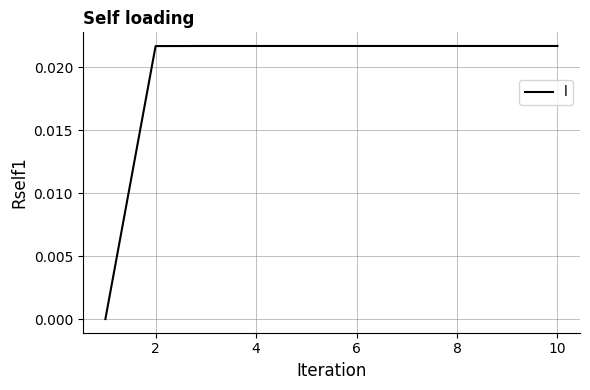

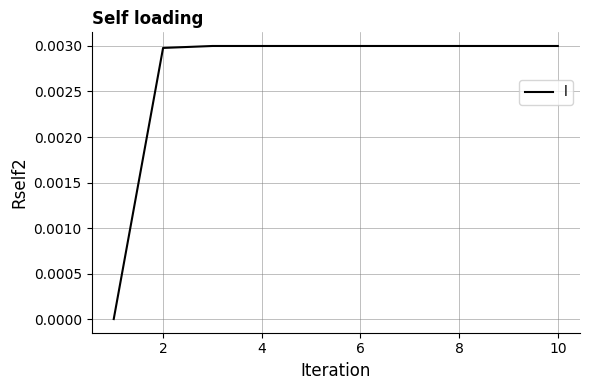

In [246]:
##Self loading loop
d['cltot_cc'] = 1.3
N_iter = 10
rself1 = np.zeros(N_iter)
rself2 = np.zeros(N_iter)
for i in range(N_iter):

    d['rself_1'] = rself1[i]
    d['rself_2'] = rself2[i]
    
    m1,m2,m3,m4,p = two_stage_sr_opti_noSC(nmos4, pmos4, s, d)
    if i+1 < N_iter:
        rself1[i+1] = p['rself1'].item()
        rself2[i+1] = p['rself2'].item()

ID1 = m1['ID']
ID2 = m2['ID']
GMID1 = m1['GM_ID']
GMID2 = m2['GM_ID']
ID_TOT = ID1 + ID2
idx = np.nanargmin(ID_TOT)

idx_beta, idx_cl = np.unravel_index(idx, ID_TOT.shape)
IDtot_opt    = ID_TOT[idx_beta, idx_cl]
cltot_cc_opt = d['cltot_cc']

print(f"cltot_cc_opt      = {cltot_cc_opt:.4f}")
print(f"IDtot_opt = {IDtot_opt*1e6:.4f}")

xaxis = np.linspace(1,N_iter, N_iter)
adri.coolPlot(xaxis, rself1, "Iteration", "Rself1", "Self loading")
adri.coolPlot(xaxis, rself2, "Iteration", "Rself2", "Self loading")


## Step 5 : Compute design param with Slew rate optimisation 

In [262]:
###FInal Design
#Design Spec 
##CGS2_CC loop
####Self loading loop
#######test several beta & gm_id to find lowest current point
#=> Take point with lowest current for CGS2_CC
#Design Spec 
s = {
    'fu1'       : 1e6,
    'fp2'       : 0,
    'vod_noise' : 900e-6,
    'L0' : 1000,
    'Cload' : 10e-12,
}
s['fp2'] = s['fu1'] * 4.0

d = {
    'L1': 0.2,
    'L2': 5,
    'L3': 0.5,
    'L4': 0.5,
    'gam1': 0.8,
    'gam2': 0.8,
    'gam3': 0.8,
    'gam4': 0.8,
    'gm3_gm1': 1,
    'gm4_gm2': 0.5,
    'cgs2_cc': 0.5,
    'rself_1': 0,
    'rself_2': 0,
    'cltot_cc': np.linspace(0.2, 1.5, 30),
    'gm_id_test': np.linspace(5, 20, 30)
    }

#Either sweep variable or use the optimal found before
# d['beta'] = np.array([beta_max * 0.8444])
# d['cltot_cc'] = np.array([1.4])
# d['gm_id_test'] = np.array([15])

cgs2_cc_iter = 10
rself_iter = 5
cgs2_cc = np.linspace(0.1,0.6,cgs2_cc_iter)
cgs2_cc = [0.3]

cgs2_cc_iter = len(cgs2_cc)
rself1 = np.zeros(rself_iter)
rself2 = np.zeros(rself_iter)
rself1_out = np.zeros(rself_iter)
rself2_out = np.zeros(rself_iter)

ITOT_PLOT = np.zeros(cgs2_cc_iter)
CGS2_CC_PLOT = np.zeros(cgs2_cc_iter)
cltot_cc_PLOT = np.zeros(cgs2_cc_iter)
beta_opt_PLOT = np.zeros(cgs2_cc_iter)
GMID_opt_PLOT = np.zeros(cgs2_cc_iter)
rself1_opt_PLOT = np.zeros(cgs2_cc_iter)
rself2_opt_PLOT = np.zeros(cgs2_cc_iter)

for k in range(len(cgs2_cc)):
    d['cgs2_cc'] = cgs2_cc[k]
    for i in range(rself_iter):
        d['rself_1'] = rself1[i]
        d['rself_2'] = rself2[i]
        m1,m2,m3,m4,p = two_stage_sr_opti_noSC(nmos4, pmos4, s, d)
    
    #print(p['rself1'])
    ID1 = m1['ID']
    ID2 = m2['ID']
    ID_TOT = ID1 + ID2
    idx = np.nanargmin(ID_TOT)
    ID_TOT = np.atleast_2d(ID_TOT)
    idx_beta, idx_cl = np.unravel_index(idx, ID_TOT.shape)
    IDtot_opt    = ID_TOT[idx_beta, idx_cl]
    cltot_cc_opt = d['cltot_cc'][idx_cl]
    GMID_opt    = m1['GM_ID'][idx_beta, idx_cl]
    #Plots / cgs_2_cc opti
    ITOT_PLOT[k] = IDtot_opt
    CGS2_CC_PLOT[k] = cgs2_cc[k]
    cltot_cc_PLOT[k] = cltot_cc_opt
    GMID_opt_PLOT[k] = GMID_opt
    rself1_opt_PLOT[k] = p['rself1'][idx_beta, idx_cl]
    rself2_opt_PLOT[k] = p['rself2'][idx_beta, idx_cl]

idx_min_cgs2_cc_loop = np.argmin(ITOT_PLOT)
#final design
###Take point where current is minimized for cgs2/cc
d['cltot_cc'] = cltot_cc_PLOT[idx_min_cgs2_cc_loop]
d['cgs2_cc'] = CGS2_CC_PLOT[idx_min_cgs2_cc_loop]
d['gm_id_test'] = np.unique(GMID_opt_PLOT[idx_min_cgs2_cc_loop])
d['rself_1'] = rself1_opt_PLOT[idx_min_cgs2_cc_loop]
d['rself_2'] = rself2_opt_PLOT[idx_min_cgs2_cc_loop]

m1,m2,m3,m4,p = two_stage_sr_opti_noSC(nmos4, pmos4, s, d)
adri.print_design_summary(s, d, p, {}, m1, m2, m3, m4)

In [263]:
# Extraction pour les MOS
mos_data = [('M1', m1), ('M2', m2), ('M3', m3), ('M4', m4)]

for name, mos in mos_data:
    w_val = mos['W'].flatten()[0]
    l_val = mos['L']
    print(f"{name}_W {w_val:.3f}u")
    print(f"{name}_L {l_val:.2f}u")

# Extraction pour les Capacités
caps = [('cc', p['cc']), ('cn', p['cn']), ('cl', p['cl'])]

for name, val in caps:
    val_f = val.flatten()[0] * 1e15
    print(f"{name} {val_f:.1f}f")

# Extraction correcte de la valeur scalaire
valeur_ibias = m1['ID'].flatten()[0] *1e6
valeur_ibias2 = m2['ID'].flatten()[0] *1e6
valeur_rz = p['rz'].flatten()[0]
# Application du formatage avec 'f' (pour le suffixe)
print(f"ibias {valeur_ibias:.3f}u")
print(f"ibias2 {valeur_ibias2:.3f}u")
print(f"rz {valeur_rz:.3f}")

M1_W 8.449u
M1_L 0.20u
M2_W 70.027u
M2_L 5.00u
M3_W 6.813u
M3_L 0.50u
M4_W 5.019u
M4_L 0.50u
cc 16571.4f
cn 1.7f
cl 10000.0f
ibias 5.684u
ibias2 35.678u
rz 2213.370


# Method 2 : Simplified method

In [249]:
# s = {
#     'G'         : 1/4,
#     'FO'        : 4,
#     'fu1'       : 0,
#     'fp2'       : 0,
#     'vod_noise' : 90e-6,
#     'L0' : 10000,
#     'ts' : 50e-9,
#     'vod_final' : 200e-3,
#     'ed'    : 0.1/100
# }
# # Constants for another design
# d = {
#     'L1': 0.5,
#     'L4': 0.5,
#     'L2': 0.5,
#     'L3': 0.5,
#     'gam1': 0.8,
#     'gam4': 0.8,
#     'gam2': 0.8,
#     'gam3': 0.8,
#     'gm3_gm1': 1.0,
#     'gm4_gm2': 0.5,
#     'cgs2_cc': 0.5,
#     'rself_1': 0,
#     'rself_2': 0,
#     'beta': beta_max * np.linspace(0.4, 0.9, 10),
#     'cltot_cc': np.linspace(0.2, 1.5, 10),
#     'gm_id_test': np.linspace(1, 30,15),
#     }
# #Compute UGBW with settling and error, 
# #step 1
# s['fu1'] = 1/(2*np.pi) * np.log(1/ s['ed']) / s['ts'] * 1
# s['fp2'] = s['fu1'] * 4.0
# #step 2
# d['rself_1'] = 0.4
# d['rself_2'] = 0.4
# #step3
# d['cgs2_cc'] = 1/3
# #step4
# beta_max = 1 / (1 + s['G'])
# d['beta'] =beta_max * 3/4
# #step5
# d['cltot_cc'] = 1.3
# #step6 -> 10, loop to adjust FU1 and rse
# # lf a few time
# for i in range(10):
#     m1,m2,m3,m4,p = adri.two_stage_sr_opti(nmos4, pmos4, s, d)
#     ##Update rself
#     d['rself_1'] = p['rself1'].item()
#     d['rself_2'] = p['rself2'].item()
#     X = s['vod_final'] * d['beta'] / 2 * m1['GM_ID']
#     actual_ts = 1 / s['fu1'] / (2 * np.pi) * (X - 1 + np.log(1/s['ed'] * X))    
#     #Update FP1

#     wu1 = 1 / s['ts']*(X - 1 + np.log(1/(s['ed']*X)))
#     s['fu1'] =  wu1.item() / (2 * np.pi)
#     s['fp2'] = s['fu1'] * 4.0
#     idtot = (m1['ID'] + m2['ID'])*1e6

# adri.cool_print(idtot,actual_ts, X, wu1, s['fu1'])



# #adri.cool_print(idtot, X,wu1,  actual_ts)
# adri.print_design_summary(s, d, p, {}, m1, m2, m3, m4)